<img src="http://authenticsimplicity.net/wp-content/uploads/2018/07/How-to-Block-Pop-Up-Ads-on-Google-Chrome-on-Desktop.jpg">

#                                  Advertisements Images detection -U.C.I

#### This dataset represents a set of possible advertisements on Internet pages. 
<h3>The features encode :-</h3> 
- the geometry of the image (if available) 
- phrases occuring in the URL
- the image's URL and alt text
- the anchor text, 
- words occuring near the anchor text
<h4 style="color:red"> The task is to predict whether an image is an advertisement ("ad") or not ("nonad")<\h4>


-The aim is to classify based on the given features given the features mentioned




#### Attribute Information:

(3 continous; others binary; this is the "STANDARD encoding" mentioned in the [Kushmerick, 99].) 

One or more of the three continous features are missing in 28% of the instances; missing values should be interpreted as "unknown".



### Importing resources and toolkits


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import collections
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import  cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

%matplotlib inline
import os
os.listdir()

['__output__.json', '__notebook__.ipynb']

* ### Exploring the dataset
1.  'df' is dataframe
2. Add.csv is the datafile 

## How datafile looks?

* There are total 1500 (PCA+ real features) as coulumns

In [2]:
df=pd.read_csv('../input/add.csv',low_memory=False,header=0)
df.head()

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,1549,1550,1551,1552,1553,1554,1555,1556,1557,1558
0,0,125,125,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ad.
1,1,57,468,8.2105,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ad.
2,2,33,230,6.9696,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ad.
3,3,60,468,7.8,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ad.
4,4,60,468,7.8,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ad.


### Remove unwanted columns
1. Here Unnamed column is removed 
2. Typecasted all columns into integers

In [3]:
df=df.drop('Unnamed: 0',axis=1)

df.columns=df.columns.astype('int')

### Columns Information
- First three colums are important as most of the variation between results are because of first three continuous varibles

* column1-> height of image
* column2->widht of image
* column30->aspect ratio

In [4]:
df.dtypes.head(3)

0    object
1    object
2    object
dtype: object

## *Information regarding Data 
* Rows: 3279 entries, 0 to 3278
* Columns: 1559 entries, 0 to 1558



In [5]:
print(df.info()) # data set information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3279 entries, 0 to 3278
Columns: 1559 entries, 0 to 1558
dtypes: int64(1554), object(5)
memory usage: 39.0+ MB
None


####  Information of First three continous variables
- 28% data is missing for three continous attributes

In [6]:
df.iloc[:,0:3].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3279 entries, 0 to 3278
Data columns (total 3 columns):
0    3279 non-null object
1    3279 non-null object
2    3279 non-null object
dtypes: object(3)
memory usage: 77.0+ KB


## Cleaning Data

Since we can see that missing values are there so first we have to replace missing values
- yellow strips represent the missing data

In [7]:
df[0][10]

'   ?'

* here '  ?'  are string values for missing data which has to be reformatted before modelling

AxesSubplot(0.125,0.125;0.775x0.755)


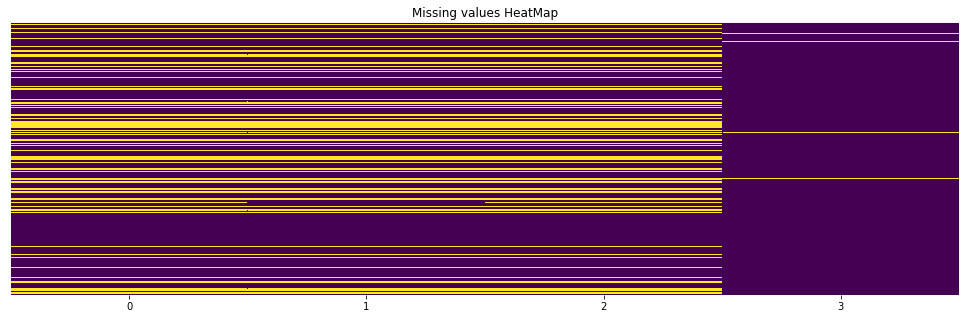

In [8]:
newdf=df.iloc[:,[0,1,2,3]]
newdf=newdf.applymap(lambda x:'?' in x)
plt.figure(figsize=(17,5))
plt.title("Missing values HeatMap")
print(sns.heatmap(newdf,cbar=False,yticklabels=False,cmap='viridis'))


####  Frequency of missing values

In [9]:
for i in (newdf):
    print('column['+str(i)+'] has missing values -'+str(sum(newdf[i])))

column[0] has missing values -903
column[1] has missing values -901
column[2] has missing values -910
column[3] has missing values -15


#### Filling missing data with mean of each attribute

1. Fill missing values with the aggregated mean of non null values
2. convert data to float to get more precision

#### replace_missing(df) is replacing missing values for top 4 features with maximum variance





In [10]:
def replace_missing(df):
    for i in df:
        df[i]=df[i].replace('[?]',np.NAN,regex=True).astype('float')
        df[i]=df[i].fillna(df[i].mean())
    return df


#### Calling replace_missing function in important features

In [11]:
df[[0,1,2,3]]=replace_missing(df.iloc[:,[0,1,2,3]].copy()).values

### Rounding off the values to Get a nominal output 
* .  Here Lambda function is used to convert float value into rounded decimal

In [12]:
df[3]=df[3].apply(lambda x:round(x))

## Exporatory  Data Analysis(E.D.A)

In statistics, exploratory data analysis (EDA) is an approach to analyzing data sets to summarize their main characteristics, often with visual methods. A statistical model can be used or not, but primarily EDA is for seeing what the data can tell us beyond the formal modeling or hypothesis testing task.

## Statsitical approach
### 1. Data is right skewed

In [13]:
df[[0,1,2,3]].describe()

,0,1,2,3
count,3279.000000,3279.000000,3279.000000,3279.000000
mean,64.021886,155.344828,3.911953,0.768222
std,46.703695,110.729038,5.136153,0.422032
min,1.000000,1.000000,0.001500,0.000000
25%,32.500000,90.000000,1.279400,1.000000
50%,64.021886,150.000000,3.911953,1.000000
75%,64.021886,155.344828,3.911953,1.000000
max,640.000000,640.000000,60.000000,1.000000


## Skewness

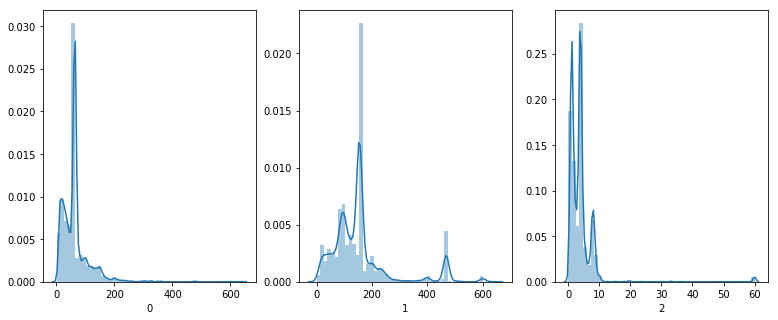

In [14]:

fig,ax=plt.subplots(nrows=1,ncols=3)
fig.set_figheight(5)
fig.set_figwidth(13)
sns.distplot(df[0],ax=ax[0])
sns.distplot(df[1],ax=ax[1])
sns.distplot(df[2],ax=ax[2])


## Relations between three continous variables

## *Here pairPlot represents the Grid Matrix of features *

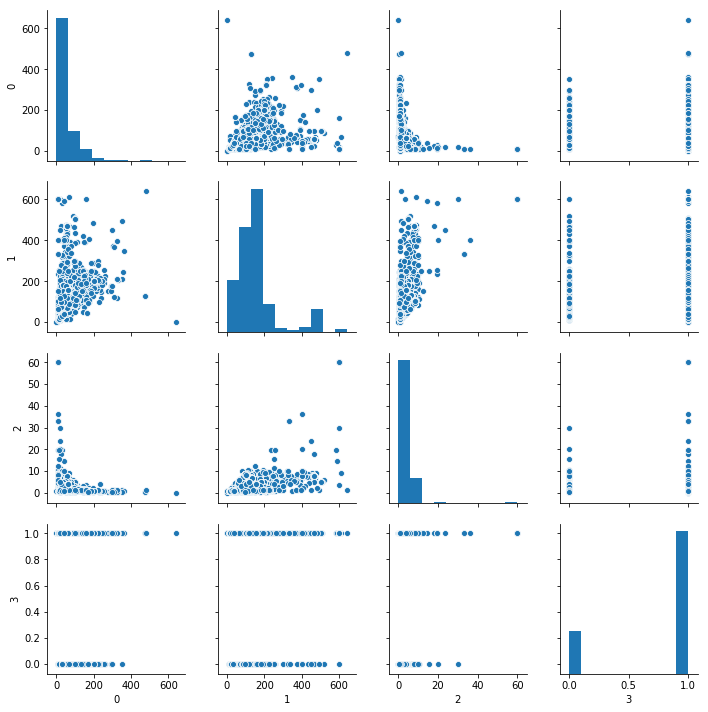

In [15]:
sns.pairplot(data=df.iloc[:,[0,1,2,3,1558]])

## *Plotting discrete data
*  ### Strip plot is showing the variance in data
* ###  Plot is showing relation between each column and all features



                                              add/non-ad  vs   Features


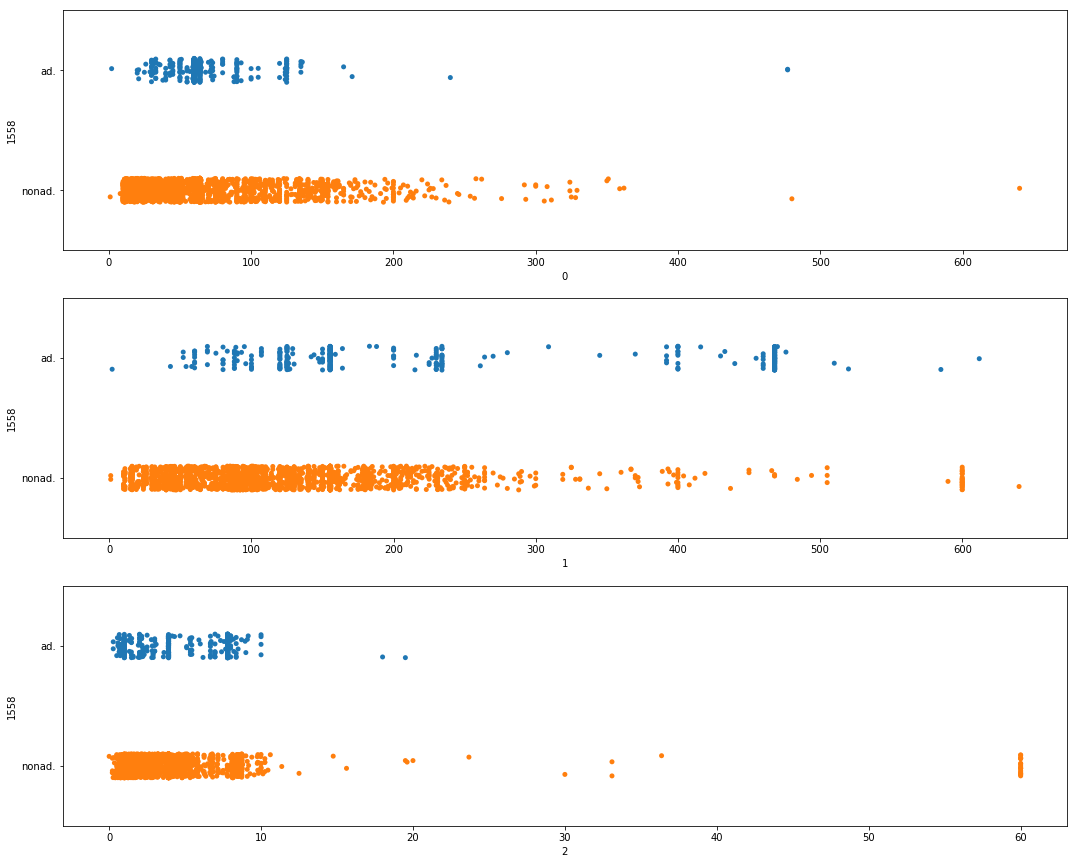

In [16]:
print("                                              add/non-ad  vs   Features")
fig,ax=plt.subplots(nrows=3,ncols=1)
fig.set_figheight(15)
fig.set_figwidth(18)
sns.stripplot(y=1558,x=0,data=df,ax=ax[0])
sns.stripplot(y=1558,x=1,data=df,ax=ax[1])
sns.stripplot(y=1558,x=2,data=df,ax=ax[2])
plt.show()

#   Frequency of Target Classes (unstable data)
* ### ad- is very low  in frequecny
* ### non-ad  is very high in frequecy

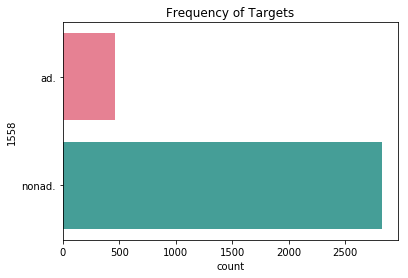

In [17]:
sns.countplot(data=df,y=1558,palette='husl')
plt.title("Frequency of Targets")
plt.show()

## - How data and central tendency is distributed 
## - Boxplot helps to see the difference in quartiles,mean and the outliers

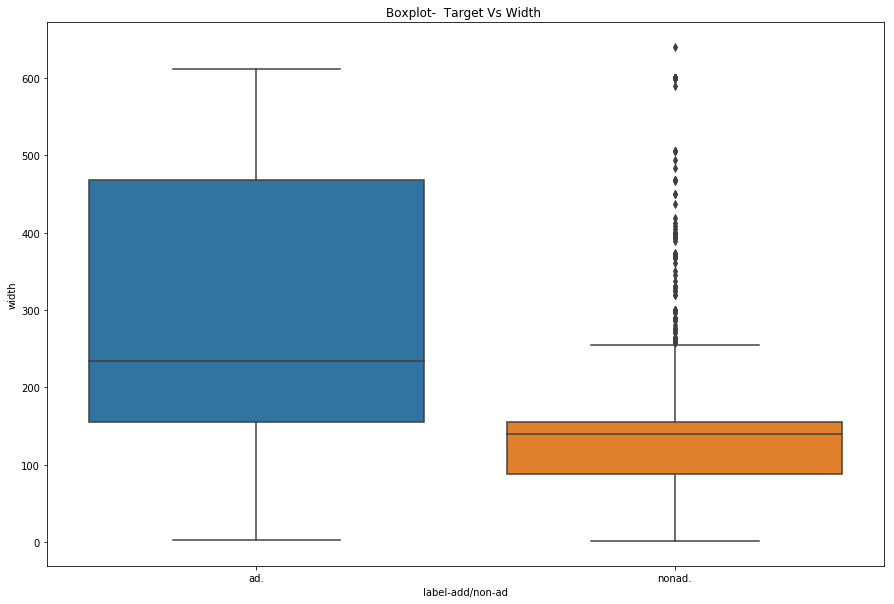

In [18]:
plt.figure(figsize=(15,10))
sns.boxplot(x=1558,y=1,data=df)
plt.xlabel('label-add/non-ad')
plt.ylabel('width')
plt.title("Boxplot-  Target Vs Width ")
plt.show()

### Insigths of Boxplot
1. Here we can see that very high number of outliers in nonad target
2. non ad is highly skewed
3. width of ad is much more as compared to nonad

# Feature Engineering

## Encoding last column(class variable)
 What is the Problem with Categorical Data?
Some algorithms can work with categorical data directly.

For example, a decision tree can be learned directly from categorical data with no data transform required (this depends on the specific implementation).

Many machine learning algorithms cannot operate on label data directly. They require all input variables and output variables to be numeric.

In general, this is mostly a constraint of the efficient implementation of machine learning algorithms rather than hard limitations on the algorithms themselves.

This means that categorical data must be converted to a numerical form. If the categorical variable is an output variable, you may also want to convert predictions by the model back into a categorical form in order to present them or use them in some application. 

* '0' - non advertisement image
* '1' - addvertisement image

In [19]:
df.iloc[:,-1]=df.iloc[:,-1].replace(['ad.','nonad.'],[1,0])

#### Preparing features for model

1. Here x stores the processed features of the model
2. Here y stores the processed labels of the model

In [20]:
x=df.iloc[:,:-1]
y=df.iloc[:,-1]

 ## Scaling data

Feature Scaling is a technique to standardize the independent features present in the data in a fixed range. It is performed during the data pre-processing to handle highly varying magnitudes or values or units. ... So, we use Feature Scaling to bring all values to same magnitudes and thus, tackle this issue.
- Since the data is highly varied and hence mikowski mertric would have a large varition of distances given a small change
- gradient decent will not work effective unless all input attributes are scaled to a same version

In [21]:
scaled=StandardScaler()
x=scaled.fit_transform(x)

## More seperable data after Scaling 
- We can see that EDA becomes more clear after scaling data 

/opt/conda/lib/python3.6/site-packages/statsmodels/nonparametric/kde.py:487: RuntimeWarning: invalid value encountered in true_divide
  binned = fast_linbin(X, a, b, gridsize) / (delta * nobs)
/opt/conda/lib/python3.6/site-packages/statsmodels/nonparametric/kdetools.py:34: RuntimeWarning: invalid value encountered in double_scalars
  FAC1 = 2*(np.pi*bw/RANGE)**2


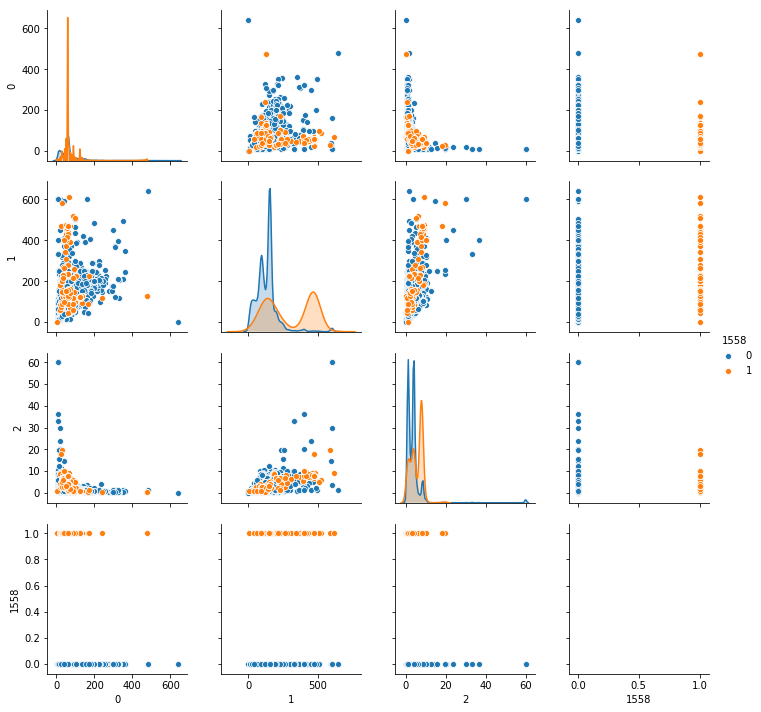

In [22]:
sns.pairplot(data=df.iloc[:,[0,1,2,-1]],hue=1558)
plt.show()

# Model Selection Pipeline
- Splitting data 
- applying models
- k fold cross vaidations
- building classification confusion matrix

# Splitting data 
1. Training &  Validation
![](https://image.slidesharecdn.com/largescaleml-151230181704/95/challenges-on-distributed-machine-learning-11-638.jpg?cb=1453938360)

## xtrain,xtest,ytrain,ytest are Partitioned data

In [23]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.30,random_state=8)

# Architecting a ML Pipeline
![](https://miro.medium.com/max/1426/1*ElodORq2cRIXfKMy8F7a-w.png)

In [24]:



def fit_models(classifiers,xtrain,ytrain):
    """This function fit multiple models by sklearn and return the dictionary with values as  objects of models"""
    models=collections.OrderedDict()
    for constructor in classifiers:
        obj=constructor()
        obj.fit(xtrain,ytrain)
        models[str(constructor).split(':')[0]]=obj
    return models

def classification_multi_report(ytest,models_array):
    """This function generate classification accuracy report for given input model objects"""
    for i in models_array:
        print('__________________________________________________')
        print('the model - '+str(i))
        print(classification_report(ytest,models_array[i].predict(xtest)))
def cross_Fucntion(models,cv):
    """This function return cross validated accuray and the variance of given input model obejects"""
    accuracy={}
    for model in models:
        cross_val_array=cross_val_score(models[model],xtrain,ytrain,scoring='accuracy',cv=cv)
        accuracy[model]=[np.mean(cross_val_array),np.std(cross_val_array)]
    return accuracy

def multi_grid_search(param_grid_array,estimator_list,x,y):
    """This function calculate the grid search parameters and accuracy  for given input modles and return dictionary with each tupple containing accuracy and best parameters"""
    d={}
    count=0
    for i in estimator_list:
        gc=GridSearchCV(estimator=estimator_list[i],param_grid=param_grid_array[count],scoring ='accuracy',cv=5).fit(x,y)
        d[i]=(gc.best_params_,gc.best_score_)
        count+=1
    return d

## **Fitting the train data **
Algorithms used are
1. >GaussianNB 
2. >KNeighbors
3. >SVM


## Classification  Report

>The classification report visualizer displays the precision, recall, F1, and support scores for the model. ... Visual classification reports are used to compare classification models to select models that are “redder”, e.g. have stronger classification metrics or that are more balanced.

In [25]:
classifiers=[GaussianNB,SVC,KNeighborsClassifier]

model_list=fit_models(classifiers,xtrain,ytrain)

classification_multi_report(ytest,model_list)

/opt/conda/lib/python3.6/site-packages/sklearn/svm/base.py:193: FutureWarning: The default value of gamma will change from 'auto' to 'scale' in version 0.22 to account better for unscaled features. Set gamma explicitly to 'auto' or 'scale' to avoid this warning.
  "avoid this warning.", FutureWarning)


__________________________________________________
the model - <class 'sklearn.naive_bayes.GaussianNB'>
              precision    recall  f1-score   support

           0       0.98      0.77      0.86       852
           1       0.38      0.89      0.53       132

    accuracy                           0.79       984
   macro avg       0.68      0.83      0.70       984
weighted avg       0.90      0.79      0.82       984

__________________________________________________
the model - <class 'sklearn.svm.classes.SVC'>
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       852
           1       0.99      0.77      0.86       132

    accuracy                           0.97       984
   macro avg       0.98      0.88      0.92       984
weighted avg       0.97      0.97      0.97       984

__________________________________________________
the model - <class 'sklearn.neighbors.classification.KNeighborsClassifier'>
              prec

* Above output shows the General model fitting of these three algorithms with Metric of evaluation

# Bias variance tradeoff

### Applying kfold cross validation to check biase and variance in the model

Cross-validation is a statistical method used to estimate the skill of machine learning models.

It is commonly used in applied machine learning to compare and select a model for a given predictive modeling problem because it is easy to understand, easy to implement, and results in skill estimates that generally have a lower bias than other methods.


In [26]:
obj=cross_Fucntion(model_list,cv=20)
for model in obj:
    print('the model -'+str(model)+'has \n || crosss validated accuracy as  -> '+str(obj[model][0])+' | variance - '+str(obj[model][1])+' ||' )
    print('______________________________________________________________________________________________________________')

/opt/conda/lib/python3.6/site-packages/sklearn/svm/base.py:193: FutureWarning: The default value of gamma will change from 'auto' to 'scale' in version 0.22 to account better for unscaled features. Set gamma explicitly to 'auto' or 'scale' to avoid this warning.
  "avoid this warning.", FutureWarning)
/opt/conda/lib/python3.6/site-packages/sklearn/svm/base.py:193: FutureWarning: The default value of gamma will change from 'auto' to 'scale' in version 0.22 to account better for unscaled features. Set gamma explicitly to 'auto' or 'scale' to avoid this warning.
  "avoid this warning.", FutureWarning)
/opt/conda/lib/python3.6/site-packages/sklearn/svm/base.py:193: FutureWarning: The default value of gamma will change from 'auto' to 'scale' in version 0.22 to account better for unscaled features. Set gamma explicitly to 'auto' or 'scale' to avoid this warning.
  "avoid this warning.", FutureWarning)
/opt/conda/lib/python3.6/site-packages/sklearn/svm/base.py:193: FutureWarning: The default 

the model -<class 'sklearn.naive_bayes.GaussianNB'>has 
 || crosss validated accuracy as  -> 0.7881701254635839 | variance - 0.03822528775418745 ||
______________________________________________________________________________________________________________
the model -<class 'sklearn.svm.classes.SVC'>has 
 || crosss validated accuracy as  -> 0.9612712065020121 | variance - 0.016718021017770278 ||
______________________________________________________________________________________________________________
the model -<class 'sklearn.neighbors.classification.KNeighborsClassifier'>has 
 || crosss validated accuracy as  -> 0.9494747363160524 | variance - 0.016180358112935368 ||
______________________________________________________________________________________________________________


# Hyperparameter optimization
From Wikipedia, the free encyclopedia
Jump to navigationJump to search
In machine learning, hyperparameter optimization or tuning is the problem of choosing a set of optimal hyperparameters for a learning algorithm. A hyperparameter is a parameter whose value is used to control the learning process. By contrast, the values of other parameters (typically node weights) are learned.

The same kind of machine learning model can require different constraints, weights or learning rates to generalize different data patterns. These measures are called hyperparameters, and have to be tuned so that the model can optimally solve the machine learning problem. Hyperparameter optimization finds a tuple of hyperparameters that yields an optimal model which minimizes a predefined loss function on given independent data.The objective function takes a tuple of hyperparameters and returns the associated loss. Cross-validation is often used to estimate this generalization performance




# Grid-search

Grid-searching is the process of scanning the data to configure optimal parameters for a given model. Depending on the type of model utilized, certain parameters are necessary. Grid-searching does NOT only apply to one model type. Grid-searching can be applied across machine learning to calculate the best parameters to use for any given model. 

In [27]:

param_grid_svm=[
    {
        'kernel':['linear'],'random_state':[0]
    },
     {
        'kernel':['rbf'],'random_state':[0]
     },
    
    {
        'kernel':['poly'],'degree':[1,2,3,4],'random_state':[0]
    }
]

param_grid_knn=[

    {   
        'n_neighbors':np.arange(1,50),
        'p':[2]
        
    }
]

param_grid_nb=[
    {}
]

param_grid_array=[param_grid_nb,param_grid_svm,param_grid_knn]
multi_grid_search(param_grid_array,model_list,xtrain,ytrain)

/opt/conda/lib/python3.6/site-packages/sklearn/svm/base.py:193: FutureWarning: The default value of gamma will change from 'auto' to 'scale' in version 0.22 to account better for unscaled features. Set gamma explicitly to 'auto' or 'scale' to avoid this warning.
  "avoid this warning.", FutureWarning)
/opt/conda/lib/python3.6/site-packages/sklearn/svm/base.py:193: FutureWarning: The default value of gamma will change from 'auto' to 'scale' in version 0.22 to account better for unscaled features. Set gamma explicitly to 'auto' or 'scale' to avoid this warning.
  "avoid this warning.", FutureWarning)
/opt/conda/lib/python3.6/site-packages/sklearn/svm/base.py:193: FutureWarning: The default value of gamma will change from 'auto' to 'scale' in version 0.22 to account better for unscaled features. Set gamma explicitly to 'auto' or 'scale' to avoid this warning.
  "avoid this warning.", FutureWarning)
/opt/conda/lib/python3.6/site-packages/sklearn/svm/base.py:193: FutureWarning: The default 

{"<class 'sklearn.naive_bayes.GaussianNB'>": ({}, 0.7934640522875817),
 "<class 'sklearn.svm.classes.SVC'>": ({'degree': 1,
   'kernel': 'poly',
   'random_state': 0},
  0.9603485838779956),
 "<class 'sklearn.neighbors.classification.KNeighborsClassifier'>": ({'n_neighbors': 3,
   'p': 2},
  0.9546840958605665)}

### Fitting model with best hyperparmater and cv score

In [28]:
classifier=SVC(kernel='poly',degree=1,random_state=0)

In [29]:
classifier.fit(xtrain,ytrain)


/opt/conda/lib/python3.6/site-packages/sklearn/svm/base.py:193: FutureWarning: The default value of gamma will change from 'auto' to 'scale' in version 0.22 to account better for unscaled features. Set gamma explicitly to 'auto' or 'scale' to avoid this warning.
  "avoid this warning.", FutureWarning)


SVC(C=1.0, cache_size=200, class_weight=None, coef0=0.0,
    decision_function_shape='ovr', degree=1, gamma='auto_deprecated',
    kernel='poly', max_iter=-1, probability=False, random_state=0,
    shrinking=True, tol=0.001, verbose=False)

## Confusion matrix for Testing data


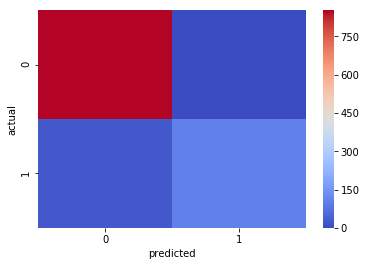

In [30]:
sns.heatmap(pd.crosstab(ytest,classifier.predict(xtest)),cmap='coolwarm')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.show()

# Result on testing data

In [31]:
print(classification_report(ytest,classifier.predict(xtest)))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98       852
           1       0.99      0.80      0.89       132

    accuracy                           0.97       984
   macro avg       0.98      0.90      0.94       984
weighted avg       0.97      0.97      0.97       984



## Clustering-
#### - we applied kmeans clustering to find out clusters based upon IMAGE   AND FEATURES

In [32]:
x=df.iloc[:,:-1].values

## Most optimal number of clusters 

## Elbow method
Recall that, the basic idea behind partitioning methods, such as k-means clustering, is to define clusters such that the total intra-cluster variation [or total within-cluster sum of square (WSS)] is minimized. The total WSS measures the compactness of the clustering and we want it to be as small as possible.

The Elbow method looks at the total WSS as a function of the number of clusters: One should choose a number of clusters so that adding another cluster doesn’t improve much better the total WSS.

The optimal number of clusters can be defined as follow:

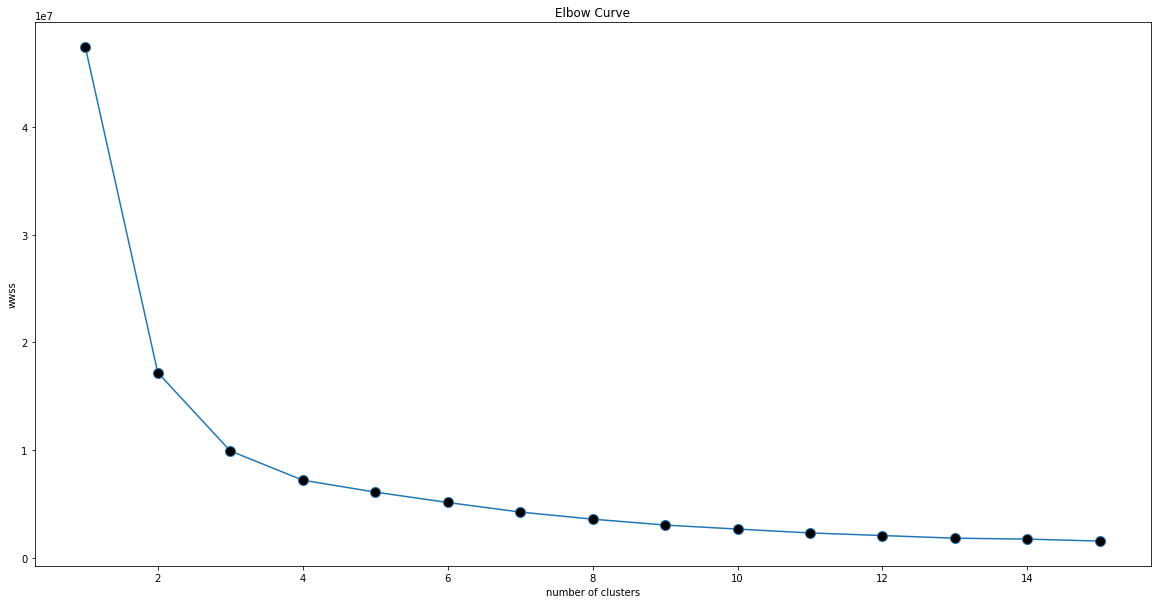

In [33]:
from sklearn.cluster import KMeans
def best_knumber_cluster(x,iter_number):
    wwss=[]
    for i in range(1,iter_number+1):
        kmeans=KMeans(n_clusters=i)
        kmeans.fit(x)
        wwss.append(kmeans.inertia_)
    plt.figure(figsize=(20,10))
    c=plt.plot(np.arange(1,iter_number+1),wwss,marker='o',markersize=10,markerfacecolor='black')
    plt.xlabel('number of clusters')
    plt.ylabel('wwss')
    plt.title('Elbow Curve')
    
    return plt.show()


best_knumber_cluster(x,15)

3 clusters are most optimal

In [34]:
kmeans=KMeans(n_clusters=3,init='k-means++',max_iter=300,n_init=100)
kmeans.fit(x)
newdf=df.copy()
newdf['Cluster']=kmeans.predict(x)


#### we can see that dimetions,aspect ratio  form 3 different cluster for given image

Text(0.5, 0, 'aspect ratio')

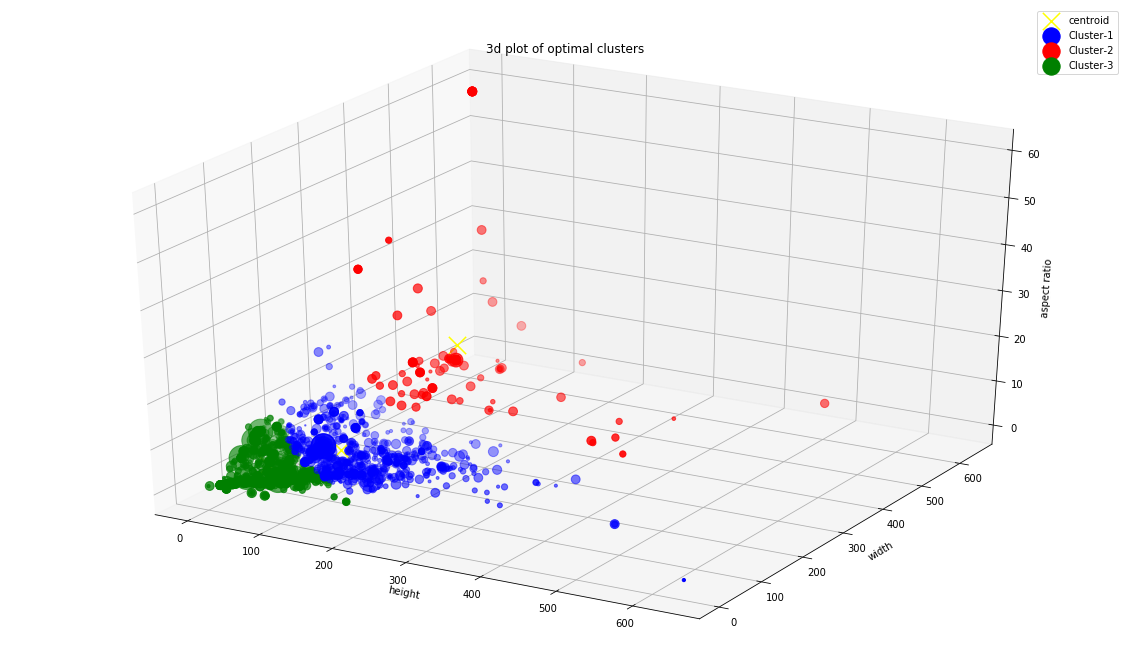

In [35]:
fig = plt.figure(figsize=(20,12))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(kmeans.cluster_centers_[0,0],kmeans.cluster_centers_[0,1],kmeans.cluster_centers_[0,2],c='yellow',marker='x',s=300)
ax.scatter(kmeans.cluster_centers_[1,0],kmeans.cluster_centers_[1,1],kmeans.cluster_centers_[1,2],c='yellow',marker='x',s=300,label='centroid')
ax.scatter(kmeans.cluster_centers_[2,0],kmeans.cluster_centers_[2,1],kmeans.cluster_centers_[2,2],c='yellow',marker='x',s=300)

ax.scatter(newdf[newdf['Cluster']==0][0],newdf[newdf['Cluster']==0][1],newdf[newdf['Cluster']==0][2],c='blue',s=newdf[2]*10,label='Cluster-1')
ax.scatter(newdf[newdf['Cluster']==1][0],newdf[newdf['Cluster']==1][1],newdf[newdf['Cluster']==1][2],c='red',s=newdf[2]*10,label='Cluster-2')
ax.scatter(newdf[newdf['Cluster']==2][0],newdf[newdf['Cluster']==2][1],newdf[newdf['Cluster']==2][2],c='green',s=newdf[2]*10,label='Cluster-3')
ax.legend()
plt.title("3d plot of optimal clusters")
plt.xlabel('height')
plt.ylabel('width')
ax.set_zlabel('aspect ratio')